In [2]:
from sympy import *
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
import time

# %matplotlib notebook
%matplotlib inline

init_printing(use_latex=True)

In [9]:
verbose = True

# Symbols
x, y = symbols('x[0] x[1]')

# Domain size
L = 1.0
H = 1.0

sx = x
sy = y

#mu = 1.0
mu = symbols('mu')
#beta = 10.0
beta = symbols('beta')
#kappa = 1.0
kappa = symbols('kappa')
gx = -((mu/kappa)*sx + beta*sqrt(sx**2 + sy**2)*sx)
gy = -((mu/kappa)*sy + beta*sqrt(sx**2 + sy**2)*sy)

p1 = integrate(gx, x)
p2 = integrate(gy, y)

source = diff(sx,x) + diff(sy,y)

print('Pressure=', p1)
print('Pressure=', p2)
print('Flux_x=', sx)
print('Flux_y=', sy)
print('Grad_x=', gx)
print('Grad_y=', gy)
print('Source=', source)




Pressure= -beta*(x[0]**2*sqrt(x[0]**2 + x[1]**2)/3 + x[1]**2*sqrt(x[0]**2 + x[1]**2)/3) - mu*x[0]**2/(2*kappa)
Pressure= -beta*(x[0]**2*sqrt(x[0]**2 + x[1]**2)/3 + x[1]**2*sqrt(x[0]**2 + x[1]**2)/3) - mu*x[1]**2/(2*kappa)
Flux_x= x[0]
Flux_y= x[1]
Grad_x= -beta*x[0]*sqrt(x[0]**2 + x[1]**2) - mu*x[0]/kappa
Grad_y= -beta*x[1]*sqrt(x[0]**2 + x[1]**2) - mu*x[1]/kappa
Source= 2


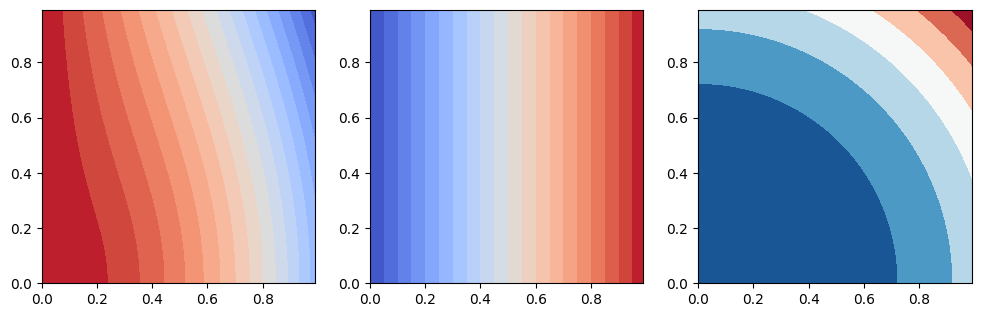

In [13]:
p = p1 -mu*y**2/(2*kappa)
pressure = lambdify([x,y],p.subs({mu:1.0,kappa:1.0,beta:10.0}))
gradx = lambdify([x,y],gx.subs({mu:1.0,kappa:1.0,beta:10.0}))
fluxx = lambdify([x,y],sx.subs({mu:1.0,kappa:1.0,beta:10.0}))
xa = np.arange(0,L,L/100)
ya = np.arange(0,H,H/100)
X,Y=np.meshgrid(xa,ya)
P = pressure(X,Y)
Gx = gradx(X,Y)
Sx = fluxx(X,Y)

fig, (ax1, ax2, ax3) = plt.subplots(1,3)
fig.set_figwidth(12)
fig.set_figheight(12)

#help(ax1.contourf)
ax1.contourf(X, Y, Gx, 20, cmap='coolwarm')
ax2.contourf(X, Y, Sx, 20, cmap='coolwarm')
ax3.contourf(X, Y, P, 20, cmap='coolwarm')
ax1.set_aspect('equal', 'box')
ax2.set_aspect('equal', 'box')
ax3.set_aspect('equal', 'box')

cp = plt.contourf(X, Y, P, cmap='RdBu')

plt.show()